In [1]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [15]:
load_dotenv

llm = ChatGoogleGenerativeAI(model = 'gemini-2.5-flash') 

In [ ]:
class JokeState(TypedDict):

  topic: str
  joke : str
  explanation : str
  dip: str


TypeError: '_TypedDictMeta' object does not support item assignment

In [29]:
def generate_joke(state: JokeState):
  prompt = f'generate small and sarcastic joke on the topic {state["topic"]}'
  response = llm.invoke(prompt).content

  return {'joke':response}

In [24]:
def generate_explanation(state: JokeState):
  prompt = f'generate the explanation for the joke - {state["joke"]}'
  response = llm.invoke(prompt).content


  return {'explanation': response}

In [25]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke',generate_joke)
graph.add_node('generate_explanation',generate_explanation)


graph.add_edge(START,'generate_joke')
graph.add_edge('generate_joke','generate_explanation')
graph.add_edge('generate_explanation',END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

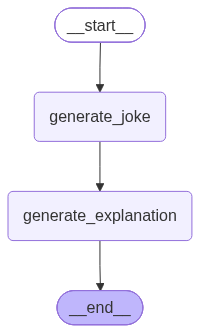

In [26]:
workflow


In [31]:
config1 = {
  "configurable" : {"thread_id":"1"}
}

workflow.invoke({'topic':'pizza'},config=config1)

{'topic': 'pizza',
 'joke': '"I love the crust! It\'s such a thoughtful palate cleanser between bites of actual pizza."',
 'explanation': 'This joke uses **sarcasm** and **irony** to express a common sentiment about pizza crust.\n\nHere\'s the breakdown:\n\n1.  **"I love the crust!"**: This starts as a seemingly genuine expression of enjoyment.\n2.  **"It\'s such a thoughtful palate cleanser..."**: This is where the sarcasm kicks in. A "palate cleanser" (like sorbet between courses or water between wine tastings) is something neutral or refreshing designed to clear your taste buds so you can better appreciate the *next* distinct flavor.\n3.  **"...between bites of actual pizza."**: This is the punchline that reveals the true meaning. By calling the crust a "palate cleanser between bites of actual pizza," the speaker is implying:\n    *   The crust itself is **not** considered "actual pizza" in terms of deliciousness.\n    *   It\'s relatively **bland**, uninteresting, or merely a neutr

In [32]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': '"I love the crust! It\'s such a thoughtful palate cleanser between bites of actual pizza."', 'explanation': 'This joke uses **sarcasm** and **irony** to express a common sentiment about pizza crust.\n\nHere\'s the breakdown:\n\n1.  **"I love the crust!"**: This starts as a seemingly genuine expression of enjoyment.\n2.  **"It\'s such a thoughtful palate cleanser..."**: This is where the sarcasm kicks in. A "palate cleanser" (like sorbet between courses or water between wine tastings) is something neutral or refreshing designed to clear your taste buds so you can better appreciate the *next* distinct flavor.\n3.  **"...between bites of actual pizza."**: This is the punchline that reveals the true meaning. By calling the crust a "palate cleanser between bites of actual pizza," the speaker is implying:\n    *   The crust itself is **not** considered "actual pizza" in terms of deliciousness.\n    *   It\'s relatively **bland**, uninteresting

In [33]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': '"I love the crust! It\'s such a thoughtful palate cleanser between bites of actual pizza."', 'explanation': 'This joke uses **sarcasm** and **irony** to express a common sentiment about pizza crust.\n\nHere\'s the breakdown:\n\n1.  **"I love the crust!"**: This starts as a seemingly genuine expression of enjoyment.\n2.  **"It\'s such a thoughtful palate cleanser..."**: This is where the sarcasm kicks in. A "palate cleanser" (like sorbet between courses or water between wine tastings) is something neutral or refreshing designed to clear your taste buds so you can better appreciate the *next* distinct flavor.\n3.  **"...between bites of actual pizza."**: This is the punchline that reveals the true meaning. By calling the crust a "palate cleanser between bites of actual pizza," the speaker is implying:\n    *   The crust itself is **not** considered "actual pizza" in terms of deliciousness.\n    *   It\'s relatively **bland**, uninterestin

In [34]:
config1 = {
  "configurable" : {"thread_id":"2"}
}

workflow.invoke({'topic':'puran-poli'},config=config2)

{'topic': 'puran-poli',
 'joke': 'Puran Poli: So much effort for something that disappears in two bites. Totally worth it. *Totally*.',
 'explanation': 'This joke plays on a very common and relatable experience for anyone who cooks, especially those who make traditional or intricate dishes. Here\'s a breakdown of why it\'s funny:\n\n1.  **Puran Poli is Labor-Intensive:**\n    *   Puran Poli is a traditional Indian sweet flatbread, particularly popular in Maharashtra. It\'s known for being quite intricate and time-consuming to make. It involves multiple steps: preparing a sweet lentil filling (puran), kneading a soft dough, carefully stuffing the puran into the dough, rolling it thinly without tearing, and then cooking it on a griddle with ghee. It requires skill and patience. The line "So much effort" perfectly captures this reality.\n\n2.  **The Contrast of Consumption:**\n    *   The phrase "disappears in two bites" highlights the stark contrast between the significant time and skill